# 06 · Deconvolving Overlapping Peaks

How to separate overlapping peaks by fitting them together, and how to let the data decide how many peaks there are.

1. Overlapping peaks keep their area when fitted together
2. BIC decides how many peaks a region holds
3. Deconvolve a whole spectrum
4. Where deconvolution breaks down

Code: `src/spectro/deconvolution.py`.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from spectro import (
    Peak,
    compare_peak_counts,
    deconvolve,
    detect_peaks,
    estimate_baseline,
    estimate_noise,
    find_regions,
    fit_peaks,
    fit_region,
    fit_table,
    make_spectrum,
    match_peaks,
    remove_baseline,
    smooth,
)


def detect(spectrum):
    noise = estimate_noise(spectrum)
    return detect_peaks(smooth(spectrum), prominence=5 * noise)


def plot_components(ax, result, table):
    x = result.userkws["x"]
    ax.plot(x, result.data, ".", ms=3, color="0.5", label="data")
    ax.plot(x, result.best_fit, color="k", lw=1, label="sum")
    for _, p in table.iterrows():
        peak = Peak(p["center"], p["fwhm"], p["height"], eta=p["eta"])
        ax.plot(x, peak.evaluate(x), lw=1)
    ax.set_xlabel("wavenumber (cm⁻¹)")
    ax.invert_xaxis()

## 1. Overlapping Peaks Keep Their Area When Fitted Together

`fit_peaks` fits each peak on its own, so each C–H band sees the other only as background and loses area. `find_regions` groups peaks whose ±2 FWHM spans overlap, and `fit_region` fits all of them at once: a sum of line shapes on one straight-line background.

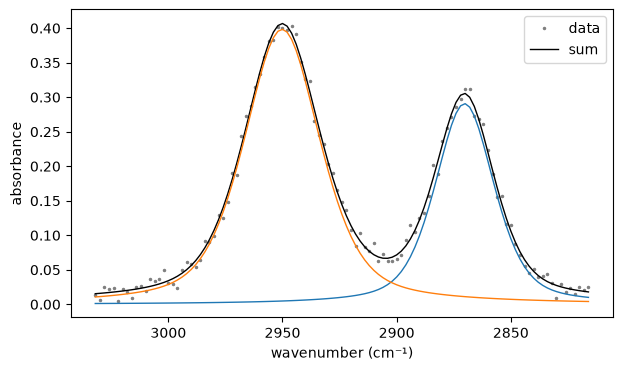

In [2]:
ch_pair = [Peak(2950, 40, 0.4), Peak(2870, 30, 0.3)]
spectrum, true_pair = make_spectrum(ch_pair, noise=0.01, seed=3)
found = detect(spectrum)
region = find_regions(found)[0]
result = fit_region(spectrum, region.peaks, region.x_range)
joint = fit_table(result, "pseudo_voigt")

fig, ax = plt.subplots(figsize=(7, 4))
plot_components(ax, result, joint)
ax.set_ylabel("absorbance")
ax.legend()
plt.show()

Fitted one at a time, both bands lose about a fifth of their area; fitted together, both come back within 3 %, inside their standard errors. Over many noise draws the joint errors contain the truth about 70 % of the time (`tests/test_deconvolution.py`), so they stay honest when the model is right.

In [3]:
single = match_peaks(fit_peaks(spectrum, found), true_pair)
together = match_peaks(joint, true_pair)
table = together[["center_true", "area_true", "area_found", "area_err_found"]]
table = table.rename(columns={"area_found": "area_joint"})
table.insert(2, "area_single", single["area_found"])
table.round(2)

,center_true,area_true,area_single,area_joint,area_err_found
0,2870,11.86,9.26,11.57,0.87
1,2950,21.08,16.69,20.61,0.82


## 2. BIC Decides How Many Peaks a Region Holds

Two equal bands 0.6 FWHM apart make a single maximum, so detection finds one peak. `compare_peak_counts` fits the region with one peak, then with one more, placed where the previous fit leaves a bump or by splitting a peak in two, and scores each fit. AIC and BIC both reward a smaller residual and charge for each extra parameter; the lowest value wins (`delta` = 0).

In [4]:
merged = [Peak(1694, 20, 0.5), Peak(1706, 20, 0.5)]
spectrum, true_merged = make_spectrum(merged, noise=0.002, seed=0)
found = detect(spectrum)
print(f"detected {len(found)} peak(s)")

region = find_regions(found)[0]
scores, results = compare_peak_counts(spectrum, region, max_extra=2)
scores.round(1)

detected 1 peak(s)


,n_peaks,chisqr,aic,bic,delta_aic,delta_bic
0,1,0.0,-530.8,-518.6,173.9,165.8
1,2,0.0,-704.8,-684.3,0.0,0.0
2,3,0.0,-703.5,-674.9,1.3,9.5


The one-peak fit leaves a clear pattern in its residual, which is what the criterion detects. A third peak improves the fit too little to pay for its four extra parameters.

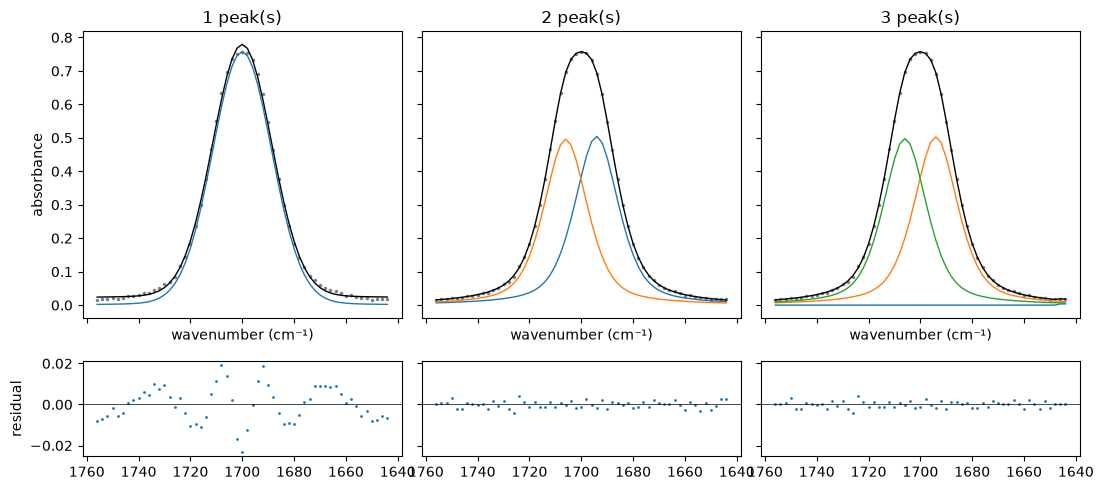

In [5]:
fig, axes = plt.subplots(
    2, 3, sharex=True, figsize=(11, 5), height_ratios=[3, 1], sharey="row"
)
for (top, bottom), fit in zip(axes.T, results, strict=True):
    plot_components(top, fit, fit_table(fit, "pseudo_voigt"))
    n = len(fit_table(fit, "pseudo_voigt"))
    top.set_title(f"{n} peak(s)")
    bottom.plot(fit.userkws["x"], fit.data - fit.best_fit, ".", ms=2)
    bottom.axhline(0, color="k", lw=0.5)
axes[0, 0].set_ylabel("absorbance")
axes[1, 0].set_ylabel("residual")
plt.tight_layout()
plt.show()

In [6]:
best = fit_table(results[int(scores["bic"].argmin())], "pseudo_voigt")
match_peaks(best, true_merged)[
    ["center_true", "center_found", "area_true", "area_found", "area_err_found"]
].round(2)

,center_true,center_found,area_true,area_found,area_err_found
0,1694,1694.11,13.18,13.51,0.33
1,1706,1706.03,13.18,13.07,0.32


## 3. Deconvolve a Whole Spectrum

`deconvolve` does both steps for every region: group the detected peaks, compare peak counts, keep the fit with the lowest BIC. On a five-band spectrum with a curved baseline (O–H, C–H pair, C=O, C–O), the C–H pair is fitted together with the O–H band, whose wide tail runs under it.

In [7]:
peaks = [
    Peak(center=3350, fwhm=300, height=0.6, shape="gaussian"),  # O–H
    Peak(center=2950, fwhm=40, height=0.4),  # C–H
    Peak(center=2870, fwhm=30, height=0.3),  # C–H
    Peak(center=1715, fwhm=25, height=0.9),  # C=O
    Peak(center=1100, fwhm=50, height=0.5, shape="lorentzian"),  # C–O
]
raw, true_peaks = make_spectrum(peaks, noise=0.01, baseline=(0.05, 0.1, -0.05), seed=3)
corrected = remove_baseline(raw)
fitted = deconvolve(corrected, detect(corrected))
match_peaks(fitted, true_peaks, tolerance=40)[
    [
        "center_true",
        "center_found",
        "fwhm_found",
        "area_true",
        "area_found",
        "region_found",
    ]
].round(2)

,center_true,center_found,fwhm_found,area_true,area_found,region_found
0,1100.0,1099.96,49.09,39.27,38.73,0
1,1715.0,1714.99,24.36,29.65,29.87,1
2,NaN,2848.34,332.45,NaN,44.15,2
3,2870.0,2870.26,29.36,11.86,9.23,2
4,2950.0,2950.31,38.65,21.08,19.09,2
5,3350.0,3350.11,297.84,191.60,188.36,2


The O–H region got a fourth component, about 330 cm⁻¹ wide, that matches no true band, and it takes area from the C–H pair, which comes out 9–22 % low. Something real in the data asks for it: on this noisy spectrum arPLS left a curved dip of up to about 0.04 under the O–H band (a known limit of arPLS on noisy spectra), which the straight-line background can't follow, so the fit uses an extra wide component. BIC can only say the data need another component, not that it is a band. On the same noise without a baseline to remove, BIC picks the right three.

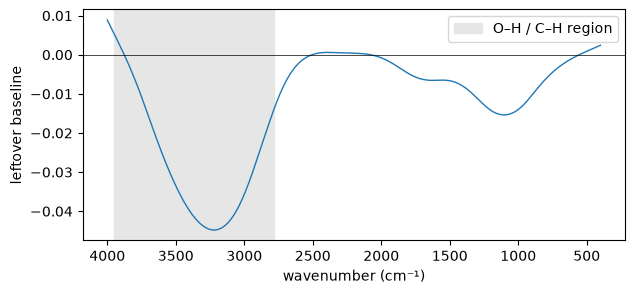

In [8]:
true_baseline = make_spectrum([], baseline=(0.05, 0.1, -0.05))[0].y
leftover = true_baseline - estimate_baseline(raw).y  # what arPLS left in
low, high = find_regions(detect(corrected))[-1].x_range

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(corrected.x, leftover, lw=1)
ax.axvspan(low, high, color="0.9", label="O–H / C–H region")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("wavenumber (cm⁻¹)")
ax.set_ylabel("leftover baseline")
ax.invert_xaxis()
ax.legend()
plt.show()

In [9]:
no_baseline, _ = make_spectrum(peaks, noise=0.01, seed=3)
region = find_regions(detect(no_baseline))[-1]
scores, _ = compare_peak_counts(no_baseline, region)
scores.round(1)

,n_peaks,chisqr,aic,bic,delta_aic,delta_bic
0,1,2.2,-3411.5,-3385.0,2233.0,2190.3
1,2,0.8,-4037.5,-3993.4,1607.0,1581.9
2,3,0.1,-5637.1,-5575.3,7.4,0.0
3,4,0.1,-5644.4,-5565.1,0.0,10.3


## 4. Where Deconvolution Breaks Down

Two equal bands (FWHM 20 cm⁻¹, height 0.5) at a controlled separation, at two noise levels, ten noise draws each. For each, count how often `deconvolve` picks two peaks, and how far the worse of the two areas is from the truth.

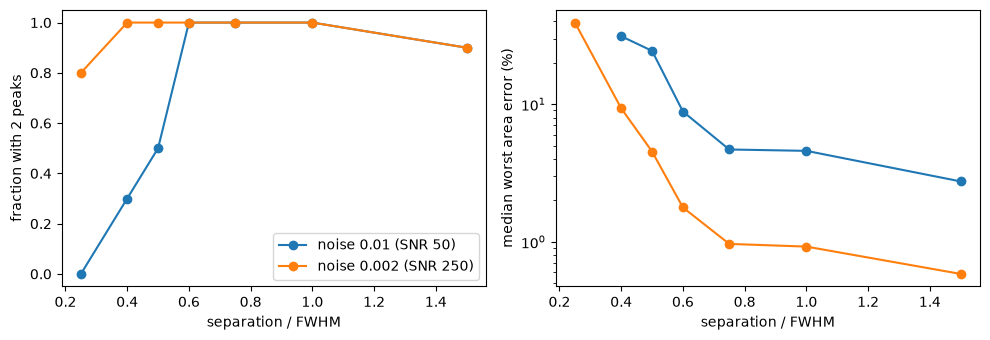

In [10]:
fwhm = 20
ratios = [0.25, 0.4, 0.5, 0.6, 0.75, 1.0, 1.5]
runs = {}
for sigma in [0.01, 0.002]:
    picked, area_error = [], []
    for ratio in ratios:
        d = ratio * fwhm
        pair = [Peak(1700 - d / 2, fwhm, 0.5), Peak(1700 + d / 2, fwhm, 0.5)]
        n_two, errors = 0, []
        for seed in range(10):
            spectrum, true = make_spectrum(pair, noise=sigma, seed=seed)
            out = deconvolve(spectrum, detect(spectrum))
            if len(out) == 2:
                n_two += 1
                errors.append(np.max(np.abs(out["area"].to_numpy() / true["area"] - 1)))
        picked.append(n_two / 10)
        area_error.append(np.median(errors) if errors else np.nan)
    runs[sigma] = (picked, area_error)

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5))
for sigma, (picked, area_error) in runs.items():
    label = f"noise {sigma} (SNR {0.5 / sigma:.0f})"
    left.plot(ratios, picked, "o-", label=label)
    right.plot(ratios, np.array(area_error) * 100, "o-", label=label)
left.set_xlabel("separation / FWHM")
left.set_ylabel("fraction with 2 peaks")
right.set_xlabel("separation / FWHM")
right.set_ylabel("median worst area error (%)")
right.set_yscale("log")
left.legend()
plt.tight_layout()
plt.show()

At noise 0.01 (signal-to-noise 50) two peaks are found every time from about 0.6 FWHM apart, with areas within about 10 %; closer than half a FWHM it usually settles for one wide peak, and when it does find two their areas are unreliable. With five times less noise the limit moves down to about 0.4 FWHM. The criterion also errs the other way now and then: at 1.5 FWHM, one draw in ten got a spurious third peak. Detection alone (`detect_peaks`) merges equal bands up to about ¾–1 FWHM, so the joint fit with BIC roughly halves the separation that can be resolved, and the limit depends on the noise.